### **Sentiment Analysis**

In [2]:
from transformers import pipeline
classifier = pipeline('sentiment-analysis')
classifier(['This is such a great movie', 'This is not a good movie at all'])

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9998791217803955},
 {'label': 'NEGATIVE', 'score': 0.9997931122779846}]

In [4]:
torch.cuda.is_available()

True

In [5]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import pipeline
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score
)

# Load dataset
df = pd.read_csv("Airline-Sentiment-2-w-AA.csv")
df = df[['text', 'airline_sentiment']].dropna()
df.head()

,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--cardiffnlp--twitter-roberta-base-sentiment-latest. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.pooler.dense.weight     | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Accuracy: 0.8086065573770492
Macro F1: 0.7593160099290702

Classification Report:

              precision    recall  f1-score   support

    negative     0.9149    0.8581    0.8856      9178
     neutral     0.6128    0.6179    0.6154      3099
    positive     0.7044    0.8663    0.7770      2363

    accuracy                         0.8086     14640
   macro avg     0.7440    0.7808    0.7593     14640
weighted avg     0.8169    0.8086    0.8109     14640



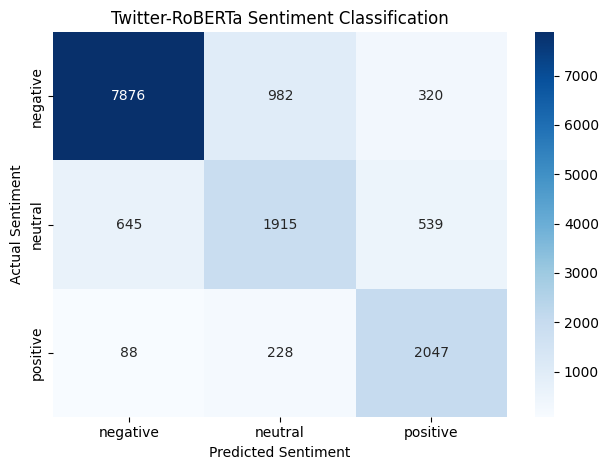

                                                text airline_sentiment  \
0                @VirginAmerica What @dhepburn said.           neutral   
1  @VirginAmerica plus you've added commercials t...          positive   
2  @VirginAmerica I didn't today... Must mean I n...           neutral   
3  @VirginAmerica it's really aggressive to blast...          negative   
4  @VirginAmerica and it's a really big bad thing...          negative   
5  @VirginAmerica seriously would pay $30 a fligh...          negative   
6  @VirginAmerica yes, nearly every time I fly VX...          positive   
7  @VirginAmerica Really missed a prime opportuni...           neutral   
8  @virginamerica Well, I didn'tÛ_but NOW I DO! :-D          positive   
9  @VirginAmerica it was amazing, and arrived an ...          positive   

  predicted_sentiment  confidence  
0             neutral    0.886301  
1            negative    0.921151  
2            negative    0.641255  
3            negative    0.914168  
4    

In [3]:
X = df['text'].astype(str).tolist()
y_true = df['airline_sentiment'].str.lower().tolist()

# Load pretrained Twitter-RoBERTa model
model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"

classifier = pipeline(
    "sentiment-analysis",
    model=model_name,
    device=0 if torch.cuda.is_available() else -1,
    batch_size=32,
    truncation=True
)

# Predict sentiment
results = classifier(X)

y_pred = [r['label'].lower() for r in results]

# Evaluate
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average='macro'))
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, digits=4))

# Confusion matrix
labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(y_true, y_pred, labels=labels)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Twitter-RoBERTa Sentiment Classification")
plt.tight_layout()
plt.show()

# Display sample predictions
df['predicted_sentiment'] = y_pred
df['confidence'] = [r['score'] for r in results]

print(df[['text', 'airline_sentiment',
          'predicted_sentiment', 'confidence']].head(10))


### **Embedding**

In [6]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity

# Load pretrained embedding model
name = "sentence-transformers/all-MiniLM-L6-v2"
tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(name)

# Documents
docs = [
    "Deep learning uses neural networks for image recognition.",
    "Transformers are widely used in natural language processing.",
    "Python is a popular programming language for data science.",
    "Convolutional neural networks are useful for computer vision.",
    "BERT generates contextual representations of text."
]

# Mean pooling with attention mask
def get_embeddings(texts):
    inputs = tokenizer(texts, padding=True, truncation=True,
                       return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)

    mask = inputs['attention_mask'].unsqueeze(-1)
    embeddings = (outputs.last_hidden_state * mask).sum(1) / mask.sum(1)
    return F.normalize(embeddings, p=2, dim=1).numpy()

# Index documents
doc_embeddings = get_embeddings(docs)

# Search
query = "Which neural networks are used for computer vision?"
query_embedding = get_embeddings([query])

scores = cosine_similarity(query_embedding, doc_embeddings)[0]
ranked = scores.argsort()[::-1]

# Display top-k results
for i in ranked[:3]:
    print(f"Score: {scores[i]:.4f} | {docs[i]}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Score: 0.6927 | Convolutional neural networks are useful for computer vision.
Score: 0.5992 | Deep learning uses neural networks for image recognition.
Score: 0.2018 | Transformers are widely used in natural language processing.


In [9]:
import numpy as np
from transformers import pipeline
from sklearn.neighbors import NearestNeighbors

# Load pretrained feature extraction pipeline
extractor = pipeline(
    "feature-extraction",
    model="sentence-transformers/all-MiniLM-L6-v2"
)

# Documents
docs = [
    "Deep learning uses neural networks for image recognition.",
    "Transformers are widely used in NLP.",
    "Python is popular for data science.",
    "CNNs are useful for computer vision.",
    "BERT generates contextual text representations."
]

def embed(texts):
    return np.vstack([
        np.mean(extractor(t, truncation=True)[0], axis=0)
        for t in texts
    ])
    
X = embed(docs)

# Build nearest-neighbor index
nn = NearestNeighbors(n_neighbors=3, metric="cosine")
nn.fit(X)

# Semantic search
query = "Which neural networks are used in computer vision?"
q = embed([query])

distances, indices = nn.kneighbors(q)

# Display top-3 matches
for i, d in zip(indices[0], distances[0]):
    print(f"Similarity: {1-d:.4f} | {docs[i]}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Similarity: 0.6780 | CNNs are useful for computer vision.
Similarity: 0.6178 | Deep learning uses neural networks for image recognition.
Similarity: 0.2286 | Transformers are widely used in NLP.


In [10]:
import pandas as pd
df = pd.read_csv('bbc_text_cls.csv')
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [11]:
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F

from transformers import pipeline
from sklearn.neighbors import NearestNeighbors

# Load pretrained feature extraction model
extractor = pipeline(
    "feature-extraction",
    model="sentence-transformers/all-MiniLM-L6-v2"
)

tokenizer = extractor.tokenizer
model = extractor.model
device = next(model.parameters()).device
model.eval()

# Load BBC documents
df = pd.read_csv("bbc_text_cls.csv")
df = df.dropna(subset=["text"]).reset_index(drop=True)
docs = df["text"].astype(str).tolist()

# Generate one embedding per document, handling long texts
def embed(texts, chunk_size=256, overlap=32, batch_size=16):

    all_embeddings = []

    for text in texts:
        # Tokenize without special tokens
        ids = tokenizer(text, add_special_tokens=False)["input_ids"]

        # Split into overlapping chunks
        step = chunk_size - overlap
        chunks = [
            tokenizer.decode(ids[i:i + chunk_size])
            for i in range(0, len(ids), step)
        ]

        chunk_embeddings = []
        chunk_weights = []

        # Extract embeddings in batches
        for start in range(0, len(chunks), batch_size):
            batch = tokenizer(
                chunks[start:start + batch_size],
                padding=True, truncation=True,
                max_length=chunk_size,
                return_tensors="pt"
            ).to(device)

            with torch.no_grad():
                outputs = model(**batch)

            # Attention-mask-aware mean pooling
            mask = batch["attention_mask"].unsqueeze(-1)
            hidden = outputs.last_hidden_state

            pooled = (hidden * mask).sum(dim=1)
            pooled = pooled / mask.sum(dim=1).clamp(min=1)

            chunk_embeddings.extend(pooled.cpu().numpy())
            chunk_weights.extend(
                batch["attention_mask"].sum(dim=1).cpu().numpy()
            )

        # Weighted average of chunk embeddings
        doc_embedding = np.average(
            chunk_embeddings, axis=0, weights=chunk_weights
        )

        all_embeddings.append(doc_embedding)

    return F.normalize(
        torch.tensor(np.array(all_embeddings), dtype=torch.float32),
        p=2, dim=1
    ).numpy()


# Build document embeddings
X = embed(docs)

print("Embedding matrix shape:", X.shape)

# Build nearest-neighbor index
nn = NearestNeighbors(n_neighbors=3, metric="cosine")
nn.fit(X)

# Semantic search
query = "Latest developments in artificial intelligence"
q = embed([query])

distances, indices = nn.kneighbors(q)

# Display top-3 matching documents
for rank, (idx, dist) in enumerate(
    zip(indices[0], distances[0]), 1
):
    print(f"\nRank: {rank} | Similarity: {1-dist:.4f}")
    print(df.iloc[idx]["text"][:500])


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Token indices sequence length is longer than the specified maximum sequence length for this model (570 > 512). Running this sequence through the model will result in indexing errors


Embedding matrix shape: (2225, 384)

Rank: 1 | Similarity: 0.3556
Robots learn 'robotiquette' rules

Robots are learning lessons on "robotiquette" - how to behave socially - so they can mix better with humans.

By playing games, like pass-the-parcel, a University of Hertfordshire team is finding out how future robot companions should react in social situations. The study's findings will eventually help humans develop a code of social behaviour in human-robot interaction. The work is part of the European Cogniron robotics project, and was on show at London's Sc

Rank: 2 | Similarity: 0.3371
Hitachi unveils 'fastest robot'

Japanese electronics firm Hitachi has unveiled its first humanoid robot, called Emiew, to challenge Honda's Asimo and Sony's Qrio robots.

Hitachi said the 1.3m (4.2ft) Emiew was the world's quickest-moving robot yet. Two wheel-based Emiews, Pal and Chum, introduced themselves to reporters at a press conference in Japan. The robots will be guests at the World Expo lat

### **Text Generation**

In [12]:
from transformers import pipeline

# Load pretrained GPT-2
generator = pipeline(
    "text-generation",
    model="openai-community/gpt2",
    device=0  # Use -1 for CPU
)

prompt = "Artificial intelligence will transform healthcare by"

# Generate three different continuations
results = generator(
    prompt,
    max_length=80,
    num_return_sequences=3,
    do_sample=True,
    temperature=0.8,
    top_k=50,
    top_p=0.95,
    repetition_penalty=1.2
)

for i, result in enumerate(results, 1):
    print(f"\nGeneration {i}:\n{result['generated_text']}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--openai-community--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: openai-community/gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Passing `generation_config` together with generation-related arguments=({'do_sample', 'max_length', 'repetition_penalty', 'temperature', 'top_k', 'top_p', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=256) and `max_length`(=80) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Generation 1:
Artificial intelligence will transform healthcare by 2025 or sooner than currently anticipated.


Generation 2:
Artificial intelligence will transform healthcare by enabling doctors, nurses and other providers to share data with each another on how they treat patients.
 A new technology known as Artificial Intelligence (AI) is taking over medicine in the U. An AI system could help physicians understand what symptoms appear when a patient has been diagnosed anorexia nervosa or bulimia because of its ability "to see" whether their body changes," says Dr. Paul Meehan, chairman at King's College London Medical Centre who was not involved in the study published online March 1."It can then tell if it would be better for all people given that those individuals may benefit from this treatment alone rather than having them suffer more harm under different conditions including certain diseases such Asperger syndrome", he explains.The research project led some members around New Yo

In [ ]:
generator = pipeline(
    "text-generation",
    model="distilbert/distilgpt2"
)

print(generator(
    "The future of machine learning is",
    max_new_tokens=60,
    num_return_sequences=2,
    do_sample=True,
    temperature=0.7
))

### **Masked Language Models**

In [13]:
from transformers import pipeline
mlm = pipeline('fill-mask')
mlm(['The cat <mask> over the box', '<mask> is considered the greatest mathematician of all time'])

No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--distilbert--distilroberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/331M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

[[{'score': 0.10449133813381195,
   'token': 13855,
   'token_str': ' jumps',
   'sequence': 'The cat jumps over the box'},
  {'score': 0.057583607733249664,
   'token': 33265,
   'token_str': ' crawling',
   'sequence': 'The cat crawling over the box'},
  {'score': 0.04840464890003204,
   'token': 33189,
   'token_str': ' leaping',
   'sequence': 'The cat leaping over the box'},
  {'score': 0.04716693237423897,
   'token': 10907,
   'token_str': ' climbing',
   'sequence': 'The cat climbing over the box'},
  {'score': 0.030807768926024437,
   'token': 32564,
   'token_str': ' leaps',
   'sequence': 'The cat leaps over the box'}],
 [{'score': 0.172288715839386,
   'token': 27648,
   'token_str': ' Einstein',
   'sequence': ' Einstein is considered the greatest mathematician of all time'},
  {'score': 0.03915267810225487,
   'token': 44849,
   'token_str': 'Marx',
   'sequence': 'Marx is considered the greatest mathematician of all time'},
  {'score': 0.030548809096217155,
   'token': 3

### **NER**

In [14]:
from transformers import pipeline
ner = pipeline('ner', aggregation_strategy='simple', device=0)
ner(['Steve Jobes was the CEO of Apple, headqaurtered in California', 'Kolkata was capital of India before the year 1911'])

No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--dbmdz--bert-large-cased-finetuned-conll03-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

[[{'entity_group': 'PER',
   'score': np.float32(0.9988639),
   'word': 'Steve Jobes',
   'start': 0,
   'end': 11},
  {'entity_group': 'ORG',
   'score': np.float32(0.99876773),
   'word': 'Apple',
   'start': 27,
   'end': 32},
  {'entity_group': 'LOC',
   'score': np.float32(0.99956983),
   'word': 'California',
   'start': 51,
   'end': 61}],
 [{'entity_group': 'LOC',
   'score': np.float32(0.9990682),
   'word': 'Kolkata',
   'start': 0,
   'end': 7},
  {'entity_group': 'LOC',
   'score': np.float32(0.9964851),
   'word': 'India',
   'start': 23,
   'end': 28}]]

In [1]:
import pickle
import numpy as np

from transformers import pipeline
from nltk.tokenize.treebank import TreebankWordDetokenizer
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Load datasets
with open("ner_train.pkl", "rb") as f:
    corpus_train = pickle.load(f)

with open("ner_test.pkl", "rb") as f:
    corpus_test = pickle.load(f)

# Extract tokens and ground-truth BIO tags
inputs, targets = [], []

for sentence_tag_pairs in corpus_test:
    tokens, tags = zip(*sentence_tag_pairs)
    inputs.append(list(tokens))
    targets.append(list(tags))

# Reconstruct original sentences
detokenizer = TreebankWordDetokenizer()
texts = [detokenizer.detokenize(tokens) for tokens in inputs]

# Load pretrained Hugging Face NER model
ner = pipeline(
    "ner",
    model="dslim/bert-base-NER",
    aggregation_strategy="simple",
    device=0  # Use -1 for CPU
)

# Convert entity spans into BIO tags aligned with original tokens
def compute_prediction(tokens, text, ner_result):

    predicted_tags = ["O"] * len(tokens)

    # Find character offsets of original tokens
    token_spans = []
    cursor = 0

    for token in tokens:
        start = text.find(token, cursor)
        if start == -1:
            raise ValueError(f"Cannot align token: {token}")

        end = start + len(token)
        token_spans.append((start, end))
        cursor = end

    # Map predicted entities to original tokens
    for entity in ner_result:
        start = entity["start"]
        end = entity["end"]
        entity_type = entity["entity_group"].upper()

        overlapping = [
            i for i, (s, e) in enumerate(token_spans)
            if s < end and e > start
        ]

        for j, idx in enumerate(overlapping):
            prefix = "B" if j == 0 else "I"
            predicted_tags[idx] = f"{prefix}-{entity_type}"

    assert len(predicted_tags) == len(tokens)
    return predicted_tags


# Perform NER
predictions = []

for tokens, text in zip(inputs, texts):
    # stride handles long inputs using overlapping chunks
    ner_result = ner(text, stride=64)

    pred = compute_prediction(tokens, text, ner_result)
    predictions.append(pred)

# Flatten targets and predictions
def flatten(list_of_lists):
    return [x for sublist in list_of_lists for x in sublist]

flat_targets = flatten(targets)
flat_predictions = flatten(predictions)

# Evaluate
print("Accuracy:", accuracy_score(flat_targets, flat_predictions))

print("Macro F1:",
      f1_score(flat_targets, flat_predictions, average="macro"))

print("\nClassification Report:\n")
print(classification_report(
    flat_targets, flat_predictions, digits=4, zero_division=0
))

# Inspect a sample
for token, actual, predicted in zip(
    inputs[9], targets[9], predictions[9]
):
    print(f"{token:20s} Actual: {actual:10s} Predicted: {predicted}")


config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--dslim--bert-base-NER. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/433M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Accuracy: 0.9859495838006966
Macro F1: 0.9386810011025761

Classification Report:

              precision    recall  f1-score   support

       B-LOC     0.9606    0.9612    0.9609      1675
      B-MISC     0.9022    0.9333    0.9174       899
       B-ORG     0.9212    0.9467    0.9338      1333
       B-PER     0.8617    0.9767    0.9157      1806
       I-LOC     0.9668    0.8859    0.9246       263
      I-MISC     0.9055    0.8450    0.8742       329
       I-ORG     0.9604    0.9424    0.9514       747
       I-PER     0.9928    0.9574    0.9748      1291
           O     0.9978    0.9930    0.9954     42474

    accuracy                         0.9859     50817
   macro avg     0.9410    0.9380    0.9387     50817
weighted avg     0.9866    0.9859    0.9861     50817

He                   Actual: O          Predicted: O
was                  Actual: O          Predicted: O
well                 Actual: O          Predicted: O
backed               Actual: O          Predicted: O


In [1]:
#import os
#print(os.path.exists("ner_train.pkl"))
#print("Files:", os.listdir())

### **Summarization**

In [1]:
# pip install "transformers>=4.45,<5"
#import os, torch
#os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
from transformers import pipeline
summarizer = pipeline(task="summarization", model="google-t5/t5-small") 
#summarizer = pipeline(task="summarization", model="facebook/bart-large-cnn", torch_dtype=torch.float16) #model="google-t5/t5-small") 
summarizer(['The shelf life of LLM findings: Owen Queen, James Zou Stanford University November 2, 2026 How long does a published finding about LLMs remain true? We revisited 50 widely cited findings about LLMs across 20 models. Within 15 months of publication, most of the LLM claims we tested either no longer held or showed substantially diminished effects. What we know about AI may have a surprisingly short shelf life. Fitted effects on September 30, 2026. How we classify claims. In 2023, Walters and Wilder asked ChatGPT to write short literature reviews and then tried to find every work it cited. At the time, ChatGPT used GPT-3.5, and 55% of its citations were fake (C11). We sent the same prompts to recent models (GPT-6.1-Sol and Claude Sonnet 5.5) and found that they rarely output fabricated citations, though some models still do. We cannot assume claims made on yesterday’s LLMs hold on today’s more capable models.'
'We test a broad range of 50 LLM claims, from sycophancy and jailbreaks to long-context capabilities and cultural biases. By analyzing 20 models, released from July 2024 to September 2026 across eight different model developers, we see how claims change as a function of model release date. Our models span large and small, open- and closed-weight. For each claim, we run the same setup across our panel of modern models and fit trend lines to how the effect changes over time. We classify claims as expired, weakened, persists, or strengthened, according to how much of the original effect remains by September 2026. A relative effect size (e) of 1 means the effect is as strong as in the paper, and 0 means it is gone. An expired claim describes an effect that has largely disappeared in newer models. We use a fifth of the paper’s effect or less as the expiration zone; a claim can expire even if the effect remains strong in some individual models. For expired claims, we estimate how long after publication the effect crossed into this expiration zone. The results below show which findings have faded, which hold up, and how long they last. Reproduction checks and metric definitions follow in How we measure claim persistence.'
'Results: Almost half (44%) of our tested claims are now expired in today’s models. Another 34% have weakened significantly, 16% persist, and 6% have strengthened relative to the original claim. Persistence varies by topic. Five of nine reasoning claims and six of eleven sycophancy-and-deception claims are classified as expired. Three of ten claims about models as judges, reviewers, and raters persist or strengthen. The three strengthened claims concern judges’ self-preference (C28), praise that follows a user’s preference (C17), and nonuniform random-number generation (C29).'
'Claims by verdict and research area. The pie shows the percentage of all claims in each category; the bars count claims within each research area. Select an area or segment to browse its claims. Which claims expire, and when Expired 22 claims Mostly capability failures that newer models no longer make: counting letters, arithmetic in other bases, finding facts in the middle of long contexts, fabricating citations, and abandoning correct answers when challenged. Other findings also faded: leaking private details from meeting summaries, more nonanswers in Arabic than in English, and preferring AI-written abstracts. The last of these reverses direction in the fitted trend, rather than merely fading to zero. Weakened 17 claims Weaker but still existent: structural limits such as the reversal curse, two-hop questions and multi-turn instructions, plus residual social biases, judges’ preference for longer answers, invented package names, niche-domain hallucinations, and susceptibility to jailbreaks and prompt injection. Persists or strengthened 8 persist · 3 strengthened Mostly preferences and judgment rather than capability: flattering and agreeing with users, judges that favor their own answers, near-identical answers to open prompts, a left political lean, and answering when they should abstain.'
'Lifetime of LLM findings How to read this plot One row per claim, in order of publication by default. The circle marks when the paper came out and is colored by the claim’s verdict in September 2026; for expired claims, a line runs to the estimated expiration date. Select Lifetime to put the longest estimated lifetimes first; claims without an estimated expiration date follow in publication order. Select Publication date to restore the original order. The active sorting button is highlighted in black. Select Show uncertainty to show an error bar for each expiration: the 95% interval of the fitted date, or, for a claim already expired on the first model released after its paper, the whole window between the paper and that model (the tick is then the window’s midpoint). A wide interval means the effect declined gradually. Select a claim to open its card. How long do claims last before they expire? Across all 50 claims, the estimated share that had expired was 4% six months after publication, 16% after one year, and 39% after two years. These estimates account for claims not yet expired at the end of observation. The share of claims still at full strength (e ≥ 0.8) falls from 64% six months after publication to 47% after one year and 31% after two years.'
'Among the 22 claims with an estimated expiration date shown in the timeline, time from publication to expiration averaged 15.7 months (median: 14.7 months). These summaries exclude claims that have not expired. Lifetimes vary widely, even within the same research area. Time to expiration by research area for expired claims Select a dot to explore the claim. The chart groups the 22 expired claims by research area. Areas that expire faster on average tend to be those optimized for in post-training pipelines, and those that take longer to expire are those more centered around bias and judgment. This roughly tracks the percentage of claims that are expired per research area. Note that the “Science, research ideas & peer review” area contains only one expired point, the fake citation claim (C11). How we calculate these durations: The life of LLM claims The claim cards show which claims have expired and how fast, ordered by when the original paper was released. Each card pairs the original paper’s evidence with the same test across model releases. Select a paper visual to enlarge it, and use dropdowns to filter by research area and verdict.'
'About the card: plots, methods & data How much of each effect remains today? Claims in the same category can still have very different effect sizes. Among weakened claims, for example, the fitted effect is about one-quarter of its reference magnitude for basic prompt injection (C2) and implicit word-association bias (C48), about one-half for the reversal curse (C13), and nearly three-quarters for legal hallucinations (C20). All are weaker than the original finding, but they are far from equally diminished. To illustrate this, we show where each claim stands as of September 30, 2026 (the last date that any of our tested models were released).'
'Every claim on a common relative effect scale: Fitted effect on September 30, 2026, with 95% intervals. e = 0 means no effect; e = 1 is the paper’s effect. Select a row to open its claim card above. A larger e means more of the original effect remains, but it does not necessarily mean the behavior is more common or more harmful. Interpreting effect sizes and uncertainty What changes from model to model?From GPT-4o mini (earliest model we tested, released in July 2024) to GPT-6.1 Sol (latest model we tested, released in September 2026), we see big shifts in the persistence of claims. The number of claims in the expiration zone rises from 5 to 30 out of 50, while the number that still hold or are stronger falls from 30 to 11. This gives a model-level view of the broad decline seen in the fitted trends. Each model’s claims are sorted from lowest to highest effect, so a claim’s horizontal position can change when you switch models; use its label or the category lists below the plot to follow it.'
'For each reliably scored model–claim pair, we apply the thresholds to that model’s measured effect e. Expired means e ≤ 0.2, without requiring its interval to lie below that threshold. Persists means 0.8 ≤ e < 1.5 and the lower bound of the 95% interval exceeds 0.2. Strengthened means e ≥ 1.5 with the same interval requirement. All remaining pairs are labeled weakened (“weaker” in the chart), including large point estimates whose intervals still reach the expiration zone. These labels describe one model on one claim, so they do not use the fitted release-date trend.'
'Compare models One model, all 50 claims. Points show effects and 95% intervals; black ticks mark our reproductions. Choose a model above the chart or inspect a category below it. Release date alone does not determine the pattern. Among models released in July–September 2026, the expired count ranges from 11 for DeepSeek V4 Pro to 30 for GPT-6.1 Sol. Qwen3.7-Flash has 14, GLM-5.3-Flash 19, and GPT-6 Luna 25. The patterns are also not perfectly aligned with model providers or model size. Hollow points are not scored reliably and are excluded from the category counts.'
'Refusals or unscorable responses The totals hide the quirks unique to individual models. Claude Sonnet 5.5’s self-preference effect (C28) is close to the paper’s magnitude (e = 1.09), whereas GPT-6.1 Sol’s is larger (e = 2.88). The pattern reverses for preference for longer answers (C27): Sonnet retains that effect (e = 1.12), while Sol’s point estimate is near the expiration value (e = 0.09). Neither model has lost every tendency: both show stronger-than-reference praise following a user’s preference (C17) (e = 1.85), and both remain highly nonuniform when asked for random numbers (C29) (e = 1.87). A claim’s panel-wide verdict can therefore differ from what you see on one model. Citation fabrication (C11) is classified as expired overall, yet Qwen3.7-Flash fabricated 69% of references in this test, compared with about 1% for Sonnet 5.5 and 0% for Sol. The plot is most useful for finding such exceptions and opening the corresponding claim card to inspect the original metric and protocol. It is a profile of measured behaviors, rather than a general-purpose model leaderboard.'
'Case Study on Hallucinated References The citation example (C11) lets us examine what a declining effect looks like in the generated text. Here, the measured outcome is the share of references that cite nonexistent works. Errors in the bibliographic details of real publications are a separate outcome. C010 Share of cited works that were fabricated, by type of work, from Walters & Wilder (2023), Table 3. The original results show why fabricated references could be difficult to spot. Among the invented articles from both GPT-3.5 and GPT-4, only 2% named a nonexistent journal. The rest named real journals, giving readers plausible-looking citations to works that did not exist. Fabrication also varied by publication type: 73% of GPT-3.5’s cited journal articles were invented. GPT-4 improved on GPT-3.5 but still fabricated 18% of its references overall.'
'We repeated the paper’s literature-review prompts across 42 topics, using GPT-3.5 Turbo as the closest available reproduction model and each model in our panel. We checked the generated references against bibliographic databases. GPT-3.5 Turbo fabricated 59% of its 210 references, close to the paper’s 55%, giving us a comparable starting point for measuring change. Citations across identical essay prompts. A struck-through reference has no matching record in the databases; a ticked one matches a real publication. The tabs show three selected prompts from the 42 topics. On the gap-year prompt, all 5 of GPT-3.5 Turbo’s references were invented: generic author names, real journals, and papers that do not exist. The recent models shown cite real studies, such as Martin (2010) in the Journal of Educational Psychology. These selected examples illustrate the difference in the outputs, and the plot below measures fabrication across all topics for each model.'
'Share of fabricated references, by model release date. The shaded expiration zone is a relative effect size (e) of 0.2 or less, a fifth of the paper’s effect. The shaded alive zone is the 95% interval of our reproduction on the paper’s model. The decline extends beyond the displayed examples. Across all topics, Claude Sonnet 5.5 fabricated 1% of its references and GPT-6.1 Sol 0%. The high fabrication rate in the original study has largely disappeared in most recent models under these prompts, although the model-level exceptions shown above remain.'
'This observation has motivated a number of policies where hallucinated references serve as a primary metric for detecting AI-generated work, a prominent concern in conferences and journals. ICLR 2026 reported desk-rejecting papers with hallucinated references, and ICML 2026 lists hallucinated references among its grounds for desk rejection. However, our results suggest that these phenomena might not occur at as high of a frequency as with older models, making such policies a poor direction to discourage AI-generated writing without human oversight. Beliefs formed around an earlier generation of models need to be tested again, and our investigation here is an example of how priors about LLM behavior must be updated with future model releases.'
'How we measure claim persistence For the claims shown and cited in the Results section, we first take a key metric from each paper and put it on a common scale that measures change relative to the paper’s result. Second, we check that we can reproduce the paper’s central result within some tolerance. Third, we run the same setup across our panel of modern models and fit trend lines to how the effect changes over time. The sections below detail these steps. Paper release dates Standardizing claims to a single scale Each claim comes with its own metric, such as fabrication rate, gap between two conditions, or entropy of a random draw. To compare them, we rescale each claim to a relative effect size e, where 1 means the effect is as strong as in the paper and 0 means it is gone. The anchor for 0 is a claim-specific expiration value: the metric value at which the claimed effect is absent.'
'e = (model value − expiration value) / (paper value − expiration value) When the expiration value is higher than the paper value, the denominator is negative, so the scale automatically reverses direction. Moving toward the expiration value still lowers e from 1 to 0, while moving beyond the paper value in the claimed direction raises e above 1. For citation fabrication (C11), the metric is the share of fabricated references: the paper value is 55%, and the expiration value is 0% (no fabricated references). Claude Sonnet 5.5 fabricated 1.37% of its references, giving e = (0.0137 − 0) / (0.55 − 0) ≈ 0.025, or about 2.5% of the paper’s effect. GPT-6.1 Sol fabricated none in our evaluation, giving e = 0.'
'The category cut-offs are on this scale. An effect at or below 0.2, a fifth of the paper’s, is in the expiration zone. At or above 0.8, it retains at least 80% of the paper’s effect. At or above 1.5 it meets the magnitude threshold for strengthened. The final categories also account for uncertainty and trend, as detailed below. Between 0.2 and 0.8 it has weakened. The shaded alive zone in the model-release plots is the 95% interval of our reproduction on the paper’s model, rescaled to e. Its bounds vary by claim and show the reproduced reference effect and its uncertainty. The 0.8 cut-off above is used for classification; the shaded band follows the reproduction’s interval.'
'Choosing the expiration value Direction and uncertainty Validating reproduction We compare reproduced effects with the paper’s reported values on the same relative-effect scale used for the panel, i.e., the paper’s effect is 1 and the claim-absent value is 0. Of the 48 claims in the numerical reproduction comparison, 25 use an exact model match while the others use substitutes or proxies. For papers whose original models were no longer available via API endpoints, we use a close match with a similar release date. We apply the same reproduction criteria to exact models, substitutes and proxies. We use agents (Claude Code and Codex) to implement the analysis pipelines and check whether they reproduce values similar to those reported in the papers. Of the 48 claims in the reproduction check below, 43 reproduce within our magnitude or uncertainty tolerance and 5 show stronger effects. (See caveats below for 2 claims not included in this count.) Reproduction criteria and examples Caveats for reproducibility Reproduced effect relative to the paper’s effect The paper’s effect is 1. Blue points reproduce within magnitude or uncertainty tolerance; orange points show stronger effects. Error bars show 95% intervals. Select a claim to open its card.'
'Fitting how each claim changes over time Single models are noisy, and models from different developers can disagree. So rather than determining a claim’s status based on a single model, we fit a smooth curve over a set of models by release date. We choose a panel of 20 models that were released between July 18, 2024 and September 29, 2026 across eight different model developers, with a slightly higher number of recently released models. Our models span large and small, open- and closed-weight. We evaluate panel models under each provider’s default API configuration. We leave reasoning effort and optional thinking modes at those defaults, without tuning effort separately for individual models. Those defaults differ across models. For example, GPT-5.2 reported no reasoning tokens in the overthinking evaluation (C36), while other models used reasoning. The comparison therefore concerns default configurations, without a common reasoning budget. In particular, the overthinking result measures token overhead in the tested configurations; it does not establish that the effect disappears when optional reasoning is enabled.'
'The curve starts at our reproduction on the paper’s model, the claim as it stood when the paper came out, and runs through the panel models released after it. Our primary criterion for an expired claim is that its fitted curve reaches e ≤ 0.2 and stays there through September 2026. An additional count of the newest models classifies two further claims as expired, as detailed below. For the other claims, the curve’s value at September 2026 gives the category. The date where the curve falls into the expiration zone gives an expired claim’s expiration date. Fitting the curve Categories and claim status certainty Expiration date Discussion While preliminary, these results teach us a few things about the current state of LLMs and their capabilities as well as empirical research of LLMs writ large.'
'Claims about LLMs have a life span In this work, we show that many LLM claims, even famous ones, disappear as LLM capabilities increase over time. Many claims made in empirical LLM literature are assumed to hold for a long time, and they often take root as perceptions the community has about LLMs. As with fabricated citations (C11), these perceptions often work their way into policies without consideration of how subsequent generations of LLMs might impact this claim. Similarly, lags in perception of LLM behavior influence AI trust and how often people use AI in their work, as explained in this tweet from Andrej Karpathy. By revisiting claims, we can more adequately shape our expectations for the failure modes and behaviors of LLMs.'
'Across the claims we tested, 16% had expired within a year of publication and 39% within two years. Among the 22 claims with an estimated expiration date shown in our plots, the time from publication to expiration averaged about 16 months, with individual lifetimes ranging from about one month to roughly three years. This average excludes claims that have not yet expired, so it is not an expected life span for all LLM findings. Even still, it shows how quickly published observations can lose relevance as models improve. On the contrary, even if a claim was made a long time ago, that doesn’t mean the claim is automatically invalid today. Four of the earliest claims we tested here (Press et al., 2022 C1; Perez & Ribeiro, 2022 C2; Li et al., 2023 C3; Wang et al., 2023 C4) are still not expired today. These aggregate persistence estimates have wide confidence intervals because the study includes only 50 claims.'
'These results exhibit how empirical LLM claims should be presented in the context of current models rather than as general truths about LLMs. A finding is an observation about particular models at a particular time, not a fixed property of language models. Because of this, papers should report the model, version and date with each result. Citing this work should carry these limitations and acknowledge that these claims might not hold up on newer models. Further, papers should include their exact provenance for reproducibility, including prompts and analysis code, in order to repeat these claims on future LLMs. Capability failures fade; preferences stay Most claims that we tested about what models cannot do have faded. Of the reasoning claims, five are expired, four have weakened, and none of them either persisted or strengthened. Some notable failures in other areas disappeared, including fabricated citations (C11), facts lost in the middle of long contexts (C7), and abandonment of correct answers when the user pushes back (C16). One hypothesis for this might be that these failures have a right answer that developers can measure and train against, accelerating progress against these effects. Importantly, many of these failures, especially high-profile ones, might have been specifically patched in post-training in recent models.'
'Claims about what models prefer have lasted longer. Of the 8 claims that persist and the 3 that strengthened, three concern models as judges or reviewers (favoring their own answers (C28), scoring accepted and rejected papers alike (C31), and rating spun trial abstracts more highly (C37)), three concern agreeing with or flattering the user (C17, C42, C43), two concern sameness (near-identical answers to open prompts (C45) and non-uniform random numbers (C29)), two concern answering when the model should decline (C10, C41), and one is a left political lean (C21). These are tendencies rather than errors on a test with one right answer, so they may be harder to notice and to train away by model developers. Social bias is a mixed case. Of the seven claims about social bias, culture and simulated populations, only the political lean (C21) persists. Three have weakened, including gender-stereotyped pronoun resolution (C9) and implicit association bias (C48). These cases highlight clear biases that LLMs can be trained against, but these biases should continue to be traced in subsequent model developments as progress continues to be made. Three of these bias claims are classified as expired: harsher judgments of speakers of African American English (C24), stereotyped personas of Black women (C5), and more nonanswers in Arabic than in English (C50). The African American English effect reverses direction in the fitted trend, with its interval entirely below zero.'
'Weakened is not expired This work also reveals some surprising failure cases in recently released models and shows the benefit of reproducing claims against LLMs over time. Some reasoning failures have shrunk without disappearing. On two-hop questions (C1), Claude Sonnet 5.5 still gets about one in ten wrong (10%) when it answers both single-hop sub-questions correctly; the paper reported 43% for ChatGPT. The reversal curse (C13) and contradictory answers to paired timeline questions (C47) have also weakened but remain measurable. Through revisiting old claims about LLMs, we can potentially derive insights on persistent problems that can help inform benchmark design or evaluation strategies for new model releases. Agentic AI and the reproducibility era In this work, we leaned on agents to reproduce papers at a rate much faster than humans could do manually. This allowed us to test many more claims in a much shorter period of time than would have been possible before coding agents. This is an example of how agentic AI can help us make science more rigorous and reproduce works at scale to gain new insights. We’re excited about future studies that take a similar approach: use agents to revisit old works and provide systematic reproducibility claims that help us advance tomorrow’s science.'
'We want your feedback! Have any questions or thoughts about this work or how it can be extended? Think we did something wrong or left out some crucial details? Have suggestions for other claims you’d want us to test? Please reach out to oqueen@stanford.edu with any comments, questions, or concerns. We’d especially love to hear from you if you’re the author of one of the papers we listed above 😄. Citation If you use this work, please cite: @misc{queen2026shelflife, title  = {The shelf life of {LLM} findings}, author = {Queen, Owen and Zou, James}, year   = {2026}, url    = {https://zou-group.github.io/llm-claims-shelf-life/}}', 'Expert human readers process large inputs (e.g., code repositories and long documents) by skimming to closely read only what matters. On the other hand, language models process all input tokens through each model layer, resulting in significant processing costs for long-context inputs. We introduce TokenGate, a small, drop-in component that extends existing trained models to enable end-to-end learnable token pruning over long-context inputs for fast and memory-efficient prefill. To enable end-to-end learning despite the non-differentiable top-K'
'operator for token pruning, we introduce token-gated attention, a mechanism inspired by Mixture-of-Experts that re-weights attention logits using token importance scores. Across diverse tasks, TokenGate achieves  1.4 11.3 × faster time-to-first token (TTFT) and 1.5 - 3.4× lower peak memory at no accuracy degradation for prefill in transformers. Compared to the best-performing prior methods for token-pruning, TokenGate gives up to 6.4 × faster prefill and  2× lower peak memory. TokenGate natively extends both standard transformers (e.g., Qwen3) and hybrid-attention models (e.g., Qwen3.5) with simple lightweight adaptation comparable to standard parameter-efficient fine-tuning. We make our code available at: https://github.com/tokengate-models/TokenGate.'])

Device set to use cuda:0
Token indices sequence length is longer than the specified maximum sequence length for this model (5826 > 512). Running this sequence through the model will result in indexing errors


[{'summary_text': 'a number of fabricated claims have disappeared in recent models . a reversal curse and implicit word-association bias have weakened . some claims have remained in the same category . we use the same set of modern models and fit trend lines .'},
 {'summary_text': 'tokenGate extends existing trained models to enable end-to-end learnable token pruning over long-context inputs . token-gated attention is a mechanism inspired by Mixture-of-Experts that re-weights attention logits using token importance scores .'}]

In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from transformers import pipeline

# Load BBC documents
df = pd.read_csv("bbc_text_cls.csv")
df = df.dropna(subset=["text"]).reset_index(drop=True)
docs = df["text"].astype(str).tolist()
#docs
summarizer = pipeline("summarization") 
summarizer(docs[0])

No model was supplied, defaulted to sshleifer/distilbart-cnn-12-6 and revision a4f8f3e (https://huggingface.co/sshleifer/distilbart-cnn-12-6).
Using a pipeline without specifying a model name and revision in production is not recommended.
'(ProtocolError('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None)), '(Request ID: b02f382c-314c-4409-941b-abc5afa236f4)')' thrown while requesting HEAD https://huggingface.co/sshleifer/distilbart-cnn-12-6/resolve/a4f8f3e/config.json
Retrying in 1s [Retry 1/5].


config.json: 0.00B [00:00, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--sshleifer--distilbart-cnn-12-6. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'summary_text': ' TimeWarner profits rose 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier . Firm is now one of the biggest investors in Google . But its own internet business, AOL, had has mixed fortunes .'}]

In [6]:
docs[0]

'Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.\n\nThe firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.\n\nTime Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL\'s underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers by offering the online service free to TimeWarner internet customers and will try to sig

## **MT**

In [7]:
from transformers import pipeline

translator = pipeline(
    "translation",
    model="facebook/nllb-200-distilled-600M"
)

text = "Artificial intelligence is transforming the world."

result = translator(
    text,
    src_lang="eng_Latn",
    tgt_lang="ben_Beng"
)

print("English:", text)
print("Bangla:", result[0]["translation_text"])

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--facebook--nllb-200-distilled-600M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/4.85M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


English: Artificial intelligence is transforming the world.
Bangla: কৃত্রিম বুদ্ধিমত্তা বিশ্বকে রূপান্তর করছে।


C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(


source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--Helsinki-NLP--opus-mt-en-es. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cuda:0
C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(
C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(
C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\nl

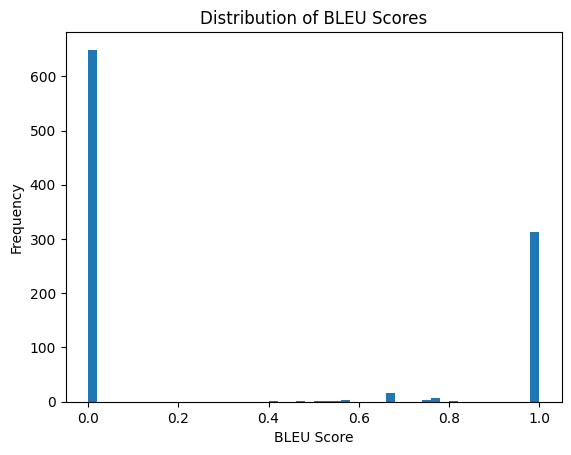

EN: Tom isn't that young.
ES Translation: Tom no es tan joven.
Matches: ['Tom no es tan joven.']


In [1]:
# Compile English-Spanish translations
eng2spa = {}

for line in open('spa.txt', encoding='utf-8'): # spa-eng
    line = line.rstrip()
    eng, spa = line.split("\t")

    if eng not in eng2spa:
        eng2spa[eng] = []

    eng2spa[eng].append(spa)

#print(eng2spa)

from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.tokenize import RegexpTokenizer

tokenizer = RegexpTokenizer(r'\w+')

tokenizer.tokenize('¿Qué me cuentas?'.lower())

tokens = tokenizer.tokenize('¿Qué me cuentas?'.lower())

sentence_bleu([tokens], tokens)

from transformers import pipeline

translator = pipeline(
    "translation",
    model="Helsinki-NLP/opus-mt-en-es",
    device=0
)

eng_phrases = list(eng2spa.keys())

eng_phrases_subset = eng_phrases[20_000:21_000]

# 27 min for 10k phrases on GPU
translations = translator(eng_phrases_subset)

# Tokenize reference translations
eng2spa_tokens = {
    eng: [
        tokenizer.tokenize(spa.lower())
        for spa in matches
    ]
    for eng, matches in eng2spa.items()
}

scores = []

for eng, pred in zip(eng_phrases_subset, translations):
    matches = eng2spa_tokens[eng]

    # Tokenize predicted translation
    spa_pred = tokenizer.tokenize(
        pred['translation_text'].lower()
    )

    score = sentence_bleu(matches, spa_pred)
    scores.append(score)

import matplotlib.pyplot as plt

plt.hist(scores, bins=50)
plt.xlabel("BLEU Score")
plt.ylabel("Frequency")
plt.title("Distribution of BLEU Scores")
plt.show()

import numpy as np

np.mean(scores)

np.random.seed(1)

def print_random_translation():
    i = np.random.choice(len(eng_phrases_subset))

    eng = eng_phrases_subset[i]
    print("EN:", eng)

    translation = translations[i]['translation_text']
    print("ES Translation:", translation)

    matches = eng2spa[eng]
    print("Matches:", matches)


print_random_translation()

### **WSD**

In [9]:
from transformers import pipeline

wsd = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    device_map="auto"
)

sentence1 = "He deposited money in the bank."
sentence2 = "The children played on the river bank."

prompt = f"""
Identify the meaning of the ambiguous word 'bank' in the following sentences:

Sentence1: {sentence1}
Sentence2: {sentence2}

Possible meanings:
1. A financial institution.
2. The land alongside a river.

Return the correct meaning in each of the sentences separately with a brief explanation.
"""

result = wsd(
    [{"role": "user", "content": prompt}],
    max_new_tokens=250,
    do_sample=False
)

print(result[0]["generated_text"][-1]["content"])

Device set to use cuda:0


Sure! Let's analyze the ambiguity of the word "bank" in each sentence to determine its correct meaning.

### Sentence 1: "He deposited money in the bank."

**Meaning:** 
- **Bank**: In this context, it refers to a financial institution where one deposits money. Banks are typically responsible for managing and processing transactions related to deposits and withdrawals.
  
**Explanation:** 
The term "bank" is used here as an abbreviation or acronym for a financial institution that handles deposit operations. It implies a place where funds are stored and managed according to banking regulations.

### Sentence 2: "The children played on the river bank."

**Meaning:** 
- **River Bank**: This phrase suggests a location along a river where people can play. Rivers often have banks where they can walk or swim, which could be considered part of the natural environment around them.

**Explanation:** 
The term "river bank" is used here as a general description of a location near a river. It impli

### **QA** 

In [10]:
from transformers import pipeline
qa = pipeline("question-answering")
ctx = "Today, I made a peanut butter sandwich"
q = "What did I put in my sandwich?"
qa(context=ctx, question=q)

No model was supplied, defaulted to distilbert/distilbert-base-cased-distilled-squad and revision 564e9b5 (https://huggingface.co/distilbert/distilbert-base-cased-distilled-squad).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--distilbert--distilbert-base-cased-distilled-squad. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


{'score': 0.7609662112372462,
 'start': 16,
 'end': 29,
 'answer': 'peanut butter'}

In [11]:
context = "Today I went to the store to purchase a carton of milk."
question = "What did I buy?"

qa(context=context, question=question)

#context[38:54]

{'score': 0.5626220703125,
 'start': 38,
 'end': 54,
 'answer': 'a carton of milk'}

In [12]:
context = "Out of all the colors, I like blue the best."
question = "What is my favorite color?"
qa(context=context, question=question)

{'score': 0.9958471059799194, 'start': 30, 'end': 34, 'answer': 'blue'}

In [13]:
context = "Albert Einstein (14 March 1879 - 18 April 1955) was a " + \
  "German-born theoretical physicist, widely acknowledged to be one of the " + \
  "greatest physicists of all time. Einstein is best known for developing " + \
  "the theory of relativity, but he also made important contributions to " + \
  "the development of the theory of quantum mechanics. Relativity and " + \
  "quantum mechanics are together the two pillars of modern physics."

question = "When was Albert Einstein born?"
qa(context=context, question=question)

{'score': 0.9411637783050537,
 'start': 17,
 'end': 30,
 'answer': '14 March 1879'}

In [14]:
question = "What was Albert Einstein's occupation?"
qa(context=context, question=question)

{'score': 0.9530766606330872,
 'start': 66,
 'end': 87,
 'answer': 'theoretical physicist'}

In [15]:
question = "What is Albert Einstein best known for?"
qa(context=context, question=question)

{'score': 0.8472640514373779,
 'start': 186,
 'end': 221,
 'answer': 'developing the theory of relativity'}

In [16]:
question = "What else has Albert Einstein contributed to?"
qa(context=context, question=question)

{'score': 0.28407326340675354,
 'start': 290,
 'end': 317,
 'answer': 'theory of quantum mechanics'}

In [17]:
question = "What are the two pillars of modern physics?"
qa(context=context, question=question)

{'score': 0.9959549868653994,
 'start': 319,
 'end': 351,
 'answer': 'Relativity and quantum mechanics'}

In [18]:
question = "Where was Albert Einstein born?"
qa(context=context, question=question)

{'score': 0.9950061440467834, 'start': 54, 'end': 60, 'answer': 'German'}

### **Zero-Shot Classification**

In [20]:
from transformers import pipeline
clf = pipeline("zero-shot-classification", device=0)
clf(
  ["This is a great movie", "It is not the case that I can say it's a good movie worth watching"],
  candidate_labels=["positive", "negative"])

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1 (https://huggingface.co/facebook/bart-large-mnli).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

C:\Users\sandi\anaconda3\envs\torch-gpu\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sandi\.cache\huggingface\hub\models--facebook--bart-large-mnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'sequence': 'This is a great movie',
  'labels': ['positive', 'negative'],
  'scores': [0.9969461560249329, 0.003053822787478566]},
 {'sequence': "It is not the case that I can say it's a good movie worth watching",
  'labels': ['negative', 'positive'],
  'scores': [0.9923288822174072, 0.0076711238361895084]}]